# Cleaning Customer file

In [2]:
import pandas as pd, numpy as np

In [3]:
customers = pd.read_csv('Customers.csv', encoding = 'latin-1')

In [4]:
customers['CustomerKey'].duplicated().sum()

np.int64(0)

In [5]:
customers

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,7/3/1939
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,9/27/1979
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,5/26/1947
3,786,Male,Jai Poltpalingada,MIDDLE RIVER,SA,South Australia,5223,Australia,Australia,9/17/1957
4,1042,Male,Aidan Pankhurst,TAWONGA SOUTH,VIC,Victoria,3698,Australia,Australia,11/19/1965
...,...,...,...,...,...,...,...,...,...,...
15261,2099600,Female,Denisa Duková,Houston,TX,Texas,77017,United States,North America,3/25/1936
15262,2099618,Male,Justin Solórzano,Mclean,VA,Virginia,22101,United States,North America,2/16/1992
15263,2099758,Male,Svend Petrussen,Wilmington,NC,North Carolina,28405,United States,North America,11/9/1937
15264,2099862,Female,Lorenza Rush,Riverside,CA,California,92501,United States,North America,10/12/1937


In [6]:
customers[customers['Zip Code'] == 'H3C 5K4' ]['City'].value_counts()

City
Montreal    37
Name: count, dtype: int64

In [7]:
customers[customers['City'] == 'ÉVREUX' ]['Zip Code'].value_counts()

Zip Code
27000    2
Name: count, dtype: int64

In [8]:
customers['Zip Code'].value_counts().sort_values()

Zip Code
3475         1
ZE2 3XW      1
TN15 9ZG     1
BD23 7XZ     1
SA4 1UX      1
            ..
V6B 3K9     27
48075       28
H3C 5K4     37
S4P 3Y2     50
90017       70
Name: count, Length: 9505, dtype: int64

In [9]:
customers[['City', 'Zip Code']].duplicated().sum()

np.int64(4716)

In [10]:
from datetime import datetime as dat
customers['Birthday'] = pd.to_datetime(customers['Birthday'], errors = 'coerce')

In [11]:
customers

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,1939-07-03
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,1979-09-27
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,1947-05-26
3,786,Male,Jai Poltpalingada,MIDDLE RIVER,SA,South Australia,5223,Australia,Australia,1957-09-17
4,1042,Male,Aidan Pankhurst,TAWONGA SOUTH,VIC,Victoria,3698,Australia,Australia,1965-11-19
...,...,...,...,...,...,...,...,...,...,...
15261,2099600,Female,Denisa Duková,Houston,TX,Texas,77017,United States,North America,1936-03-25
15262,2099618,Male,Justin Solórzano,Mclean,VA,Virginia,22101,United States,North America,1992-02-16
15263,2099758,Male,Svend Petrussen,Wilmington,NC,North Carolina,28405,United States,North America,1937-11-09
15264,2099862,Female,Lorenza Rush,Riverside,CA,California,92501,United States,North America,1937-10-12


In [12]:
customers['Country'].value_counts(normalize = True)* 100

Country
United States     44.726844
United Kingdom    12.734181
Canada            10.172933
Germany            9.648893
Australia          9.301716
Netherlands        4.801520
France             4.388838
Italy              4.225075
Name: proportion, dtype: float64

In [13]:
today = pd.Timestamp.today()

customers["Age"] = today.year - customers['Birthday'].dt.year - (today.month < customers['Birthday'].dt.month | 
                                                                 ((today.month == customers['Birthday'].dt.month) & (today.day < customers['Birthday'].dt.day)))
                                                                 

In [14]:
customers

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday,Age
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,1939-07-03,87
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,1979-09-27,47
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,1947-05-26,79
3,786,Male,Jai Poltpalingada,MIDDLE RIVER,SA,South Australia,5223,Australia,Australia,1957-09-17,69
4,1042,Male,Aidan Pankhurst,TAWONGA SOUTH,VIC,Victoria,3698,Australia,Australia,1965-11-19,61
...,...,...,...,...,...,...,...,...,...,...,...
15261,2099600,Female,Denisa Duková,Houston,TX,Texas,77017,United States,North America,1936-03-25,90
15262,2099618,Male,Justin Solórzano,Mclean,VA,Virginia,22101,United States,North America,1992-02-16,34
15263,2099758,Male,Svend Petrussen,Wilmington,NC,North Carolina,28405,United States,North America,1937-11-09,89
15264,2099862,Female,Lorenza Rush,Riverside,CA,California,92501,United States,North America,1937-10-12,89


In [15]:
customers[customers['State Code'] == 'GBP']

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday,Age


In [16]:
customers['Age'].describe()

count    15266.000000
mean        57.774728
std         19.320142
min         24.000000
25%         41.000000
50%         58.000000
75%         74.000000
max         91.000000
Name: Age, dtype: float64

In [17]:
customers.to_csv('Customers_Cleaned.csv', index = False)

# Cleaning Sales File

In [18]:
sales = pd.read_csv('sales.csv')

In [19]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Order Number   62884 non-null  int64
 1   Line Item      62884 non-null  int64
 2   Order Date     62884 non-null  str  
 3   Delivery Date  13165 non-null  str  
 4   CustomerKey    62884 non-null  int64
 5   StoreKey       62884 non-null  int64
 6   ProductKey     62884 non-null  int64
 7   Quantity       62884 non-null  int64
 8   Currency Code  62884 non-null  str  
dtypes: int64(6), str(3)
memory usage: 4.3 MB


In [20]:
sales.shape

(62884, 9)

In [21]:
sales.columns

Index(['Order Number', 'Line Item', 'Order Date', 'Delivery Date',
       'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code'],
      dtype='str')

In [22]:
sales[['Order Number', 'Line Item']].duplicated().sum()

np.int64(0)

In [23]:
sales['Line Item'].value_counts()

Line Item
1    26326
2    16789
3    10248
4     5125
5     2175
6     1476
7      745
Name: count, dtype: int64

In [24]:
sales['Order Date'] = pd.to_datetime(sales['Order Date'], errors = 'coerce')

In [25]:
sales['Delivery Date'] = pd.to_datetime(sales['Delivery Date'], errors = 'coerce')

In [26]:
sales['StoreKey'].value_counts().sort_index()

StoreKey
0     13165
1       292
2        18
4       431
5       892
6       615
8      1360
9      1577
10     1269
12      224
13      184
14      126
15      235
16      214
17      210
18      194
19      635
20      443
21      391
22      800
23      674
24      703
26      295
27      721
28      214
29     1011
30      976
31      417
32      454
33      498
34      448
36     1049
37      995
38     1034
39     1054
40     1050
41      444
42     1017
43     1340
44     1436
45     1471
47     1348
48     1289
49     1041
50     1519
51     1356
53     1284
54     1498
55     1518
56     1287
57     1442
59     1472
61     1485
62      778
63      948
64     1353
65     1395
66     1295
Name: count, dtype: int64

In [27]:
sales['ProductKey'].value_counts()

ProductKey
423     162
458     158
446     158
434     158
448     157
       ... 
2326      1
2319      1
2311      1
216       1
193       1
Name: count, Length: 2492, dtype: int64

In [28]:
sales['Quantity'].value_counts()

Quantity
1     18311
2     13611
3     10907
4      5441
6      3699
7      3639
5      3619
8      1849
10      913
9       895
Name: count, dtype: int64

In [29]:
sales['Currency Code'].value_counts()

Currency Code
USD    33767
EUR    12621
GBP     8140
CAD     5415
AUD     2941
Name: count, dtype: int64

In [30]:
temp = sales.groupby('Order Number')['Line Item'].transform('nunique') > 1
sales[temp]['Line Item'].max()

np.int64(7)

In [31]:
valid = sales['Delivery Date'] - sales['Order Date']

In [32]:
valid.dropna().value_counts()

4 days     2735
3 days     2518
5 days     2189
6 days     1592
2 days     1480
7 days      967
1 days      549
8 days      519
9 days      280
10 days     173
11 days      81
12 days      45
13 days      17
15 days       8
14 days       7
17 days       5
Name: count, dtype: int64

In [33]:
sales['Order Date'].max()

Timestamp('2021-02-20 00:00:00')

In [34]:
# sales data is okay

# Cleaning Product File

In [35]:
products = pd.read_csv('Products.csv')

In [36]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ProductKey      2517 non-null   int64
 1   Product Name    2517 non-null   str  
 2   Brand           2517 non-null   str  
 3   Color           2517 non-null   str  
 4   Unit Cost USD   2517 non-null   str  
 5   Unit Price USD  2517 non-null   str  
 6   SubcategoryKey  2517 non-null   int64
 7   Subcategory     2517 non-null   str  
 8   CategoryKey     2517 non-null   int64
 9   Category        2517 non-null   str  
dtypes: int64(3), str(7)
memory usage: 196.8 KB


In [37]:
def find_duplicates(df: pd.DataFrame):
    for col in df.columns:
        print(col ,':', df[col].duplicated().sum())
    

In [38]:
find_duplicates(products)

ProductKey : 0
Product Name : 0
Brand : 2506
Color : 2501
Unit Cost USD : 2037
Unit Price USD : 2091
SubcategoryKey : 2485
Subcategory : 2485
CategoryKey : 2509
Category : 2509


In [39]:
products.duplicated().sum()

np.int64(0)

In [40]:
for col in products.columns:
    if (col == 'ProductKey' or col =='Product Name'):
        continue
    print(products[col].value_counts())

Brand
Contoso                 710
Fabrikam                267
Litware                 264
Proseware               244
Adventure Works         192
Southridge Video        192
Wide World Importers    173
The Phone Company       152
Tailspin Toys           144
A. Datum                132
Northwind Traders        47
Name: count, dtype: int64
Color
Black          602
White          505
Silver         417
Grey           283
Blue           200
Red             99
Pink            84
Brown           77
Green           74
Orange          55
Gold            50
Yellow          36
Azure           14
Silver Grey     14
Purple           6
Transparent      1
Name: count, dtype: int64
Unit Cost USD
$15.29      34
$321.44     29
$210.72     29
$52.00      28
$152.94     27
            ..
$23.86       1
$198.39      1
$24.83       1
$13.26       1
$1.50        1
Name: count, Length: 480, dtype: int64
Unit Price USD
$29.99      30
$699.00     29
$635.99     29
$129.00     28
$299.00     28
            ..
$

In [41]:
products['Unit Cost USD'] = products['Unit Cost USD'].apply(lambda x : x.split('$')[1])

In [42]:
products['Unit Price USD'] = products['Unit Price USD'].apply(lambda x : x.split('$')[1])

In [44]:
products['Unit Cost USD'].apply(lambda x: x.split(','))

0        [6.62 ]
1        [6.62 ]
2        [7.40 ]
3       [11.00 ]
4       [11.00 ]
          ...   
2512    [43.07 ]
2513    [43.07 ]
2514     [1.71 ]
2515     [1.71 ]
2516     [1.71 ]
Name: Unit Cost USD, Length: 2517, dtype: object

In [45]:
def remove_comma(string:str):
    if ',' in string:
        temp = string.split(',')
        digit = temp[0] + temp[1]
    else:
        digit = string
    return digit
    

In [46]:
products['Unit Cost USD'] = products['Unit Cost USD'].apply(remove_comma)
products['Unit Price USD'] = products['Unit Price USD'].apply(remove_comma)

In [47]:
products['Unit Cost USD'] = products['Unit Cost USD'].astype('float32')
products['Unit Price USD'] = products['Unit Price USD'].astype('float32')

In [48]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ProductKey      2517 non-null   int64  
 1   Product Name    2517 non-null   str    
 2   Brand           2517 non-null   str    
 3   Color           2517 non-null   str    
 4   Unit Cost USD   2517 non-null   float32
 5   Unit Price USD  2517 non-null   float32
 6   SubcategoryKey  2517 non-null   int64  
 7   Subcategory     2517 non-null   str    
 8   CategoryKey     2517 non-null   int64  
 9   Category        2517 non-null   str    
dtypes: float32(2), int64(3), str(5)
memory usage: 177.1 KB


In [49]:
products['Subcategory'].value_counts(normalize = True)*100

Subcategory
Computers Accessories               7.985697
Lamps                               6.277314
Download Games                      4.767580
Projectors & Screens                4.092173
Camcorders                          4.092173
Microwaves                          4.052443
Printers, Scanners & Fax            4.012714
Smart phones & PDAs                 4.012714
Home Theater System                 3.972984
Digital Cameras                     3.972984
Digital SLR Cameras                 3.972984
Home & Office Phones                3.655145
Movie DVD                           3.575685
Refrigerators                       3.416766
Laptops                             3.098927
Monitors                            3.098927
Fans                                3.098927
Coffee Machines                     2.940008
Washers & Dryers                    2.781089
Cameras & Camcorders Accessories    2.741359
Touch Screen Phones                 2.463250
Air Conditioners                    2.46325

In [50]:
products[products['Unit Cost USD'] > products['Unit Price USD']]

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category


In [51]:
products.to_csv('Products_Cleaned.csv', index = False)

# Cleaning Store File

In [52]:
stores = pd.read_csv('stores.csv')

In [53]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   StoreKey       67 non-null     int64  
 1   Country        67 non-null     str    
 2   State          67 non-null     str    
 3   Square Meters  66 non-null     float64
 4   Open Date      67 non-null     str    
dtypes: float64(1), int64(1), str(3)
memory usage: 2.7 KB


In [54]:
stores.duplicated().sum()

np.int64(0)

In [55]:
find_duplicates(stores)

StoreKey : 0
Country : 58
State : 0
Square Meters : 30
Open Date : 42


In [56]:
stores

,StoreKey,Country,State,Square Meters,Open Date
0,1,Australia,Australian Capital Territory,595.0,2008-01-01
1,2,Australia,Northern Territory,665.0,2008-01-12
2,3,Australia,South Australia,2000.0,2012-01-07
3,4,Australia,Tasmania,2000.0,2010-01-01
4,5,Australia,Victoria,2000.0,2015-12-09
...,...,...,...,...,...
62,63,United States,Utah,2000.0,2008-03-06
63,64,United States,Washington DC,1330.0,2010-01-01
64,65,United States,West Virginia,1785.0,2012-01-01
65,66,United States,Wyoming,840.0,2014-01-01


In [57]:
stores[stores['Square Meters'].isnull()]

,StoreKey,Country,State,Square Meters,Open Date
66,0,Online,Online,NaN,2010-01-01


In [58]:
stores

,StoreKey,Country,State,Square Meters,Open Date
0,1,Australia,Australian Capital Territory,595.0,2008-01-01
1,2,Australia,Northern Territory,665.0,2008-01-12
2,3,Australia,South Australia,2000.0,2012-01-07
3,4,Australia,Tasmania,2000.0,2010-01-01
4,5,Australia,Victoria,2000.0,2015-12-09
...,...,...,...,...,...
62,63,United States,Utah,2000.0,2008-03-06
63,64,United States,Washington DC,1330.0,2010-01-01
64,65,United States,West Virginia,1785.0,2012-01-01
65,66,United States,Wyoming,840.0,2014-01-01


In [59]:
stores['Open Date'] = pd.to_datetime(stores['Open Date'])

In [60]:
stores

,StoreKey,Country,State,Square Meters,Open Date
0,1,Australia,Australian Capital Territory,595.0,2008-01-01
1,2,Australia,Northern Territory,665.0,2008-01-12
2,3,Australia,South Australia,2000.0,2012-01-07
3,4,Australia,Tasmania,2000.0,2010-01-01
4,5,Australia,Victoria,2000.0,2015-12-09
...,...,...,...,...,...
62,63,United States,Utah,2000.0,2008-03-06
63,64,United States,Washington DC,1330.0,2010-01-01
64,65,United States,West Virginia,1785.0,2012-01-01
65,66,United States,Wyoming,840.0,2014-01-01


In [61]:
stores.to_csv('Stores.csv', index = False)

# Exchange Rate File

In [62]:
er = pd.read_csv('Exchange_Rates.csv')

In [63]:
er

,Date,Currency,Exchange
0,1/1/2015,USD,1.0000
1,1/1/2015,CAD,1.1583
2,1/1/2015,AUD,1.2214
3,1/1/2015,EUR,0.8237
4,1/1/2015,GBP,0.6415
...,...,...,...
11210,2/20/2021,USD,1.0000
11211,2/20/2021,CAD,1.2610
11212,2/20/2021,AUD,1.2723
11213,2/20/2021,EUR,0.8238


In [64]:
er.Date = pd.to_datetime(er.Date)

In [65]:
er.set_index('Date', inplace = True)

In [66]:
er

,Currency,Exchange
Date,,
2015-01-01,USD,1.0000
2015-01-01,CAD,1.1583
2015-01-01,AUD,1.2214
2015-01-01,EUR,0.8237
2015-01-01,GBP,0.6415
...,...,...
2021-02-20,USD,1.0000
2021-02-20,CAD,1.2610
2021-02-20,AUD,1.2723


In [67]:
er.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 11215 entries, 2015-01-01 to 2021-02-20
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Currency  11215 non-null  str    
 1   Exchange  11215 non-null  float64
dtypes: float64(1), str(1)
memory usage: 262.9 KB


In [68]:
er.duplicated().sum()

np.int64(7268)

In [69]:
!pip install seaborn
import seaborn as sns

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\mbvin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [70]:
import matplotlib.pyplot as plt

<Axes: xlabel='Date', ylabel='Exchange'>

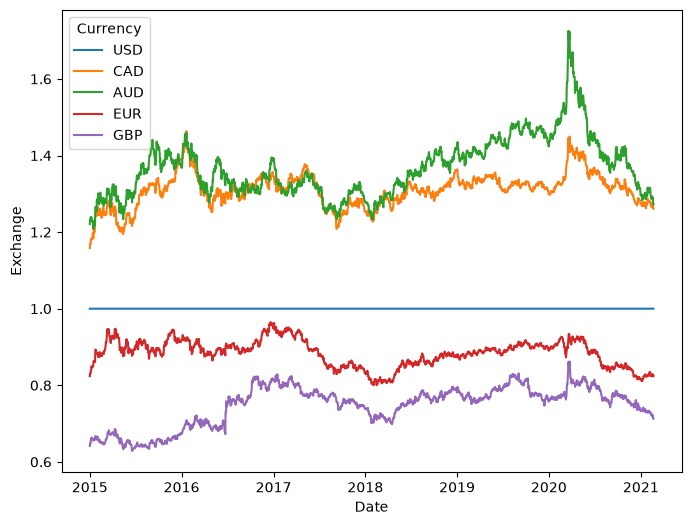

In [71]:
plt.figure(figsize = (8, 6))

sns.lineplot(data = er, x = 'Date', y = 'Exchange', hue = 'Currency')

In [72]:
er.reset_index().to_csv('ExchangeRates_Cleaned.csv', index = False)

In [75]:
sales.to_csv('Sales_Cleaned.csv', index = False)